# Referral Success Rate Predictor
### Using the Medical Appointment No-Shows dataset (Brazil, 2016)

**Goal:** given information about a referral/appointment *at the moment it is booked*, predict the probability that the patient will actually attend.

**How we frame it**

| Concept | In the dataset |
|---|---|
| Referral **success** | Patient showed up (`No-show == "No"`) |
| Referral **failure** | Patient did not show up (`No-show == "Yes"`) |
| Success rate for a referral | `1 − P(no-show)` predicted by the model |

We train the model to detect **no-shows** (the minority class, ≈20%) because that's the event we want to catch and act on (reminder calls, transport help, overbooking). The predicted *success rate* is just one minus that probability.

**Roadmap of this notebook**

1. Setup & load data
2. First look at the raw data
3. Cleaning
4. Exploratory Data Analysis (EDA)
5. Feature engineering (incl. patient history *without leakage*)
6. Train / test split (time-based)
7. Baseline model
8. Logistic Regression
9. Tree-based models
10. Evaluation — the right metrics for imbalanced data
11. Choosing a decision threshold
12. What drives predictions? (feature importance)
13. Calibration — can we trust the probabilities?
14. Saving the model & scoring a new referral
15. Exercises to deepen your learning

> 💡 Cells marked **Learning note** explain the *why*, not just the *how*. Read them — they're the point of the project.

## 1. Setup & load data

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, precision_recall_curve, brier_score_loss)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

# 👉 Change this to wherever you saved the Kaggle file
DATA_PATH = "./data/KaggleV2-May-2016.csv"
raw = pd.read_csv(DATA_PATH)
print(raw.shape)

(110527, 14)


## 2. First look at the raw data

In [12]:
raw.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [13]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  str    
 3   ScheduledDay    110527 non-null  str    
 4   AppointmentDay  110527 non-null  str    
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  str    
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  str    
dtypes: float64(1), int64(8), str(5)
memory usage: 11.8 MB


In [14]:
print("Missing values per column:\n", raw.isna().sum(), sep="")
print("\nDuplicate rows:", raw.duplicated().sum())
print("Duplicate AppointmentIDs:", raw["AppointmentID"].duplicated().sum())
raw.describe().T

Missing values per column:
PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

Duplicate rows: 0
Duplicate AppointmentIDs: 0


,count,mean,std,min,25%,50%,75%,max
PatientId,110527.0,1.474963e+14,2.560949e+14,3.921784e+04,4.172614e+12,3.173184e+13,9.439172e+13,9.999816e+14
AppointmentID,110527.0,5.675305e+06,7.129575e+04,5.030230e+06,5.640286e+06,5.680573e+06,5.725524e+06,5.790484e+06
Age,110527.0,3.708887e+01,2.311020e+01,-1.000000e+00,1.800000e+01,3.700000e+01,5.500000e+01,1.150000e+02
Scholarship,110527.0,9.826558e-02,2.976748e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
Hipertension,110527.0,1.972459e-01,3.979213e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
Diabetes,110527.0,7.186479e-02,2.582651e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
Alcoholism,110527.0,3.039981e-02,1.716856e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
Handcap,110527.0,2.224796e-02,1.615427e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
SMS_received,110527.0,3.210256e-01,4.668727e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00


**Learning note — what to look for in a first pass**

- **Typos in column names**: `Hipertension`, `Handcap`, `No-show` (the hyphen makes it awkward in code). We'll rename.
- **`Age` has a minimum of -1** → impossible value, a data-entry error.
- **`Handcap` goes up to 4** although it is described as a flag — it's actually the *number* of handicaps.
- **Dates are strings** → must be parsed before we can compute anything with them.
- **`ScheduledDay` has a time, `AppointmentDay` doesn't** (always 00:00). So for "days until appointment" we compare *dates* only.

## 3. Cleaning

In [15]:
df = raw.rename(columns={
    "Hipertension": "Hypertension",
    "Handcap": "Handicap",
    "No-show": "NoShow",
    "SMS_received": "SMSReceived",
}).copy()

# Parse dates (they are UTC strings like 2016-04-29T18:38:08Z)
df["ScheduledDay"] = pd.to_datetime(df["ScheduledDay"], utc=True)
df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"], utc=True)

# Target: 1 = no-show (referral failed), 0 = attended (referral succeeded)
df["no_show"] = (df["NoShow"] == "Yes").astype(int)

# Days between booking and appointment (date part only)
df["lead_days"] = (df["AppointmentDay"].dt.normalize() - df["ScheduledDay"].dt.normalize()).dt.days

before = len(df)
df = df[(df["Age"] >= 0) & (df["Age"] <= 110)]   # impossible ages
df = df[df["lead_days"] >= 0]                     # appointment before it was booked = error
print(f"Removed {before - len(df)} invalid rows; {len(df):,} remain")

df["is_female"] = (df["Gender"] == "F").astype(int)
df = df.drop(columns=["Gender"])
df["Handicap"] = df["Handicap"].clip(upper=1)    # turn count into a 0/1 flag (few rows >1)
df = df.drop(columns=["NoShow"])
df.head()

Removed 11 invalid rows; 110,516 remain


,PatientId,AppointmentID,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMSReceived,no_show,lead_days,is_female
0,2.987250e+13,5642903,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,0,0,1
1,5.589978e+14,5642503,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,0,0,0
2,4.262962e+12,5642549,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,0,0,1
3,8.679512e+11,5642828,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,0,0,1
4,8.841186e+12,5642494,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,0,0,1


## 4. Exploratory Data Analysis

No-show rate: 20.2%  →  overall referral success rate: 79.8%


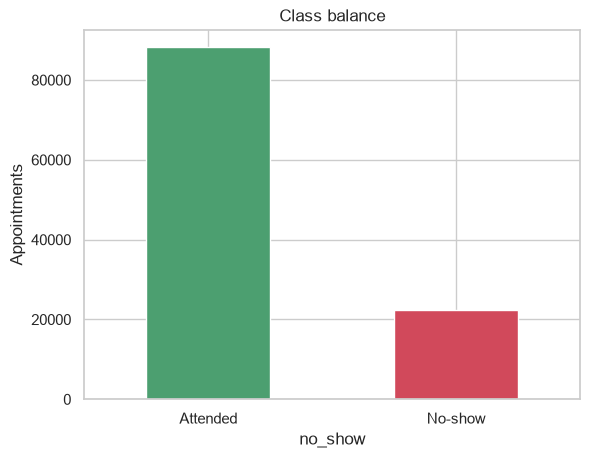

In [16]:
rate = df["no_show"].mean()
print(f"No-show rate: {rate:.1%}  →  overall referral success rate: {1-rate:.1%}")
ax = df["no_show"].map({0: "Attended", 1: "No-show"}).value_counts().plot.bar(rot=0, color=["#4C9F70", "#D1495B"])
ax.set_title("Class balance"); ax.set_ylabel("Appointments");

**Learning note — class imbalance.** Only ~1 in 5 appointments is a no-show. A model that *always* says "will attend" is already ~80% accurate, yet useless. That's why we will judge models with **ROC-AUC**, **PR-AUC** and **recall on no-shows**, not accuracy.

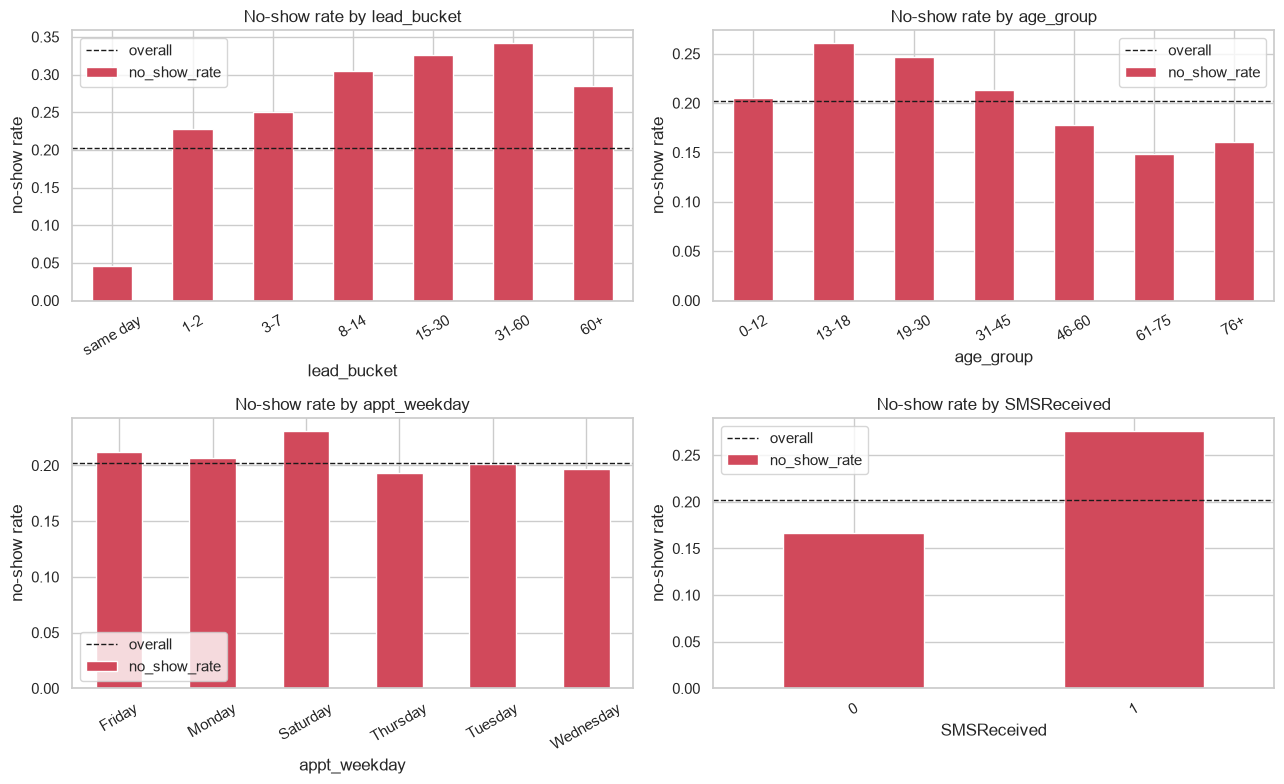

In [17]:
def rate_by(col, data=None):
    data = df if data is None else data
    return data.groupby(col, observed=True)["no_show"].agg(no_show_rate="mean", n="size")

df["lead_bucket"] = pd.cut(df["lead_days"], [-1, 0, 2, 7, 14, 30, 60, 1000],
                           labels=["same day", "1-2", "3-7", "8-14", "15-30", "31-60", "60+"])
df["age_group"] = pd.cut(df["Age"], [-1, 12, 18, 30, 45, 60, 75, 120],
                         labels=["0-12", "13-18", "19-30", "31-45", "46-60", "61-75", "76+"])
df["appt_weekday"] = df["AppointmentDay"].dt.day_name()

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), ["lead_bucket", "age_group", "appt_weekday", "SMSReceived"]):
    r = rate_by(col)
    r["no_show_rate"].plot.bar(ax=ax, rot=30, color="#D1495B")
    ax.axhline(rate, ls="--", c="k", lw=1, label="overall")
    ax.set_title(f"No-show rate by {col}"); ax.set_ylabel("no-show rate"); ax.legend()
plt.tight_layout()

**Learning note — what the plots usually show on the real data**

- **Lead time is the strongest signal.** Same-day bookings almost always attend; the longer the wait, the higher the no-show rate.
- **Young adults (≈13–30) no-show more**; older patients are more reliable.
- **The SMS paradox:** patients who received an SMS seem to no-show *more*! That's not because SMS hurts — SMS are only sent for appointments booked several days ahead, and those have higher no-show rates anyway. This is **confounding**. Check it yourself below.

In [18]:
# Untangle the SMS paradox: compare SMS vs no-SMS *within the same lead-time bucket*
pd.crosstab(df["lead_bucket"], df["SMSReceived"], values=df["no_show"], aggfunc="mean").round(3)

SMSReceived,0,1
lead_bucket,,
same day,0.046,NaN
1-2,0.227,NaN
3-7,0.266,0.238
8-14,0.338,0.281
15-30,0.369,0.298
31-60,0.383,0.315
60+,0.339,0.255


In [19]:
flags = ["Scholarship", "Hypertension", "Diabetes", "Alcoholism", "Handicap", "is_female"]
pd.DataFrame({f: df.groupby(f)["no_show"].mean() for f in flags}).T.rename(columns={0: "flag=0", 1: "flag=1"}).round(3)

,flag=0,flag=1
Scholarship,0.198,0.237
Hypertension,0.209,0.173
Diabetes,0.204,0.180
Alcoholism,0.202,0.201
Handicap,0.202,0.180
is_female,0.200,0.203


In [20]:
nb = rate_by("Neighbourhood").query("n >= 100").sort_values("no_show_rate")
print(f"{df['Neighbourhood'].nunique()} neighbourhoods; no-show rate ranges {nb.no_show_rate.min():.1%} – {nb.no_show_rate.max():.1%} (those with ≥100 appts)")
pd.concat([nb.head(5), nb.tail(5)])

81 neighbourhoods; no-show rate ranges 14.6% – 28.9% (those with ≥100 appts)


,no_show_rate,n
Neighbourhood,,
MÁRIO CYPRESTE,0.145553,371
SOLON BORGES,0.147122,469
DE LOURDES,0.154098,305
DO CABRAL,0.157143,560
SANTA MARTHA,0.158416,3131
JESUS DE NAZARETH,0.243954,2853
ITARARÉ,0.262664,3514
SANTA CLARA,0.264822,506
SANTA CECÍLIA,0.274554,448


## 5. Feature engineering

Features we'll build:

| Feature | Why |
|---|---|
| `lead_days`, `same_day` | Strongest predictor from EDA |
| `sched_hour`, `appt_weekday`, `sched_weekday` | Timing habits |
| `Age`, health flags, `Scholarship` (welfare), `SMSReceived` | Patient profile |
| `Neighbourhood` | Location / access (one-hot, rare ones grouped) |
| `prior_appts`, `prior_noshows`, `prior_noshow_rate` | **Past behaviour is the best predictor of future behaviour** |

**Learning note — data leakage (very important!)**
A tempting feature is "this patient's no-show rate" computed over the whole dataset. That uses the **outcome of the very appointment we're predicting** (and future ones) → the model looks amazing in testing and fails in real life.

The correct rule: *only use information available at the moment the referral is booked*. So for each appointment we count only the patient's appointments whose **appointment date is before the booking date** of the current one. `pd.merge_asof` does exactly this "look up the latest past value" join.

In [21]:
df["same_day"] = (df["lead_days"] == 0).astype(int)
df["sched_hour"] = df["ScheduledDay"].dt.hour
df["sched_weekday"] = df["ScheduledDay"].dt.day_name()
df["sched_date"] = df["ScheduledDay"].dt.normalize()
df["appt_date"] = df["AppointmentDay"].dt.normalize()

# --- Patient history without leakage ---
# 1) per patient & appointment date: how many appts and no-shows happened that day
daily = (df.groupby(["PatientId", "appt_date"])["no_show"].agg(n="size", ns="sum").reset_index()
           .sort_values(["PatientId", "appt_date"]))
# 2) running totals (inclusive of that day)
daily["cum_appts"] = daily.groupby("PatientId")["n"].cumsum()
daily["cum_noshows"] = daily.groupby("PatientId")["ns"].cumsum()

# 3) for each appointment, take totals from the latest appt_date STRICTLY BEFORE its booking date
left = df.reset_index().sort_values("sched_date")
right = daily[["PatientId", "appt_date", "cum_appts", "cum_noshows"]].sort_values("appt_date")
hist = pd.merge_asof(left, right, left_on="sched_date", right_on="appt_date", by="PatientId",
                     allow_exact_matches=False, suffixes=("", "_hist"))
hist = hist.set_index("index").loc[df.index]

df["prior_appts"] = hist["cum_appts"].fillna(0).astype(int)
df["prior_noshows"] = hist["cum_noshows"].fillna(0).astype(int)
df["prior_noshow_rate"] = np.where(df["prior_appts"] > 0, df["prior_noshows"] / df["prior_appts"].clip(lower=1), np.nan)
df["has_history"] = (df["prior_appts"] > 0).astype(int)
df["prior_noshow_rate"] = df["prior_noshow_rate"].fillna(0)

print(df[["prior_appts", "prior_noshows", "has_history"]].describe().round(2))
rate_by("has_history")

       prior_appts  prior_noshows  has_history
count    110516.00      110516.00    110516.00
mean          0.89           0.13         0.28
std           3.65           0.53         0.45
min           0.00           0.00         0.00
25%           0.00           0.00         0.00
50%           0.00           0.00         0.00
75%           1.00           0.00         1.00
max          83.00          15.00         1.00


,no_show_rate,n
has_history,,
0,0.217861,79638
1,0.160665,30878


> Note: the dataset covers only ~3 months of appointments, so many patients have no "past". In a real referral system with years of history, these features become much more powerful.

## 6. Train / test split — time-based

**Learning note.** A random split lets the model train on June and test on April — it "sees the future". In production we always predict *upcoming* referrals from *past* data, so we mimic that: train on earlier appointment dates, test on the latest ~20%.

In [22]:
TARGET = "no_show"
NUMERIC = ["Age", "lead_days", "sched_hour", "prior_appts", "prior_noshows", "prior_noshow_rate"]
BINARY = ["is_female", "Scholarship", "Hypertension", "Diabetes", "Alcoholism", "Handicap",
          "SMSReceived", "same_day", "has_history"]
CATEGORICAL = ["appt_weekday", "sched_weekday", "Neighbourhood"]
FEATURES = NUMERIC + BINARY + CATEGORICAL

cutoff = df["appt_date"].quantile(0.8)
train = df[df["appt_date"] <= cutoff]
test = df[df["appt_date"] > cutoff]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f"Cutoff appointment date: {cutoff.date()}")
print(f"Train: {len(train):,} rows, no-show rate {y_train.mean():.1%}")
print(f"Test : {len(test):,} rows, no-show rate {y_test.mean():.1%}")

Cutoff appointment date: 2016-06-01
Train: 88,531 rows, no-show rate 20.6%
Test : 21,985 rows, no-show rate 18.5%


## 7. Baseline

Always start with a dumb baseline so you know what "better" means.

In [23]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("bin", "passthrough", BINARY),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), CATEGORICAL),
])

results = {}
def evaluate(name, model, X=X_test, y=y_test, show=True):
    p = model.predict_proba(X)[:, 1]
    pred = (p >= 0.5).astype(int)
    results[name] = {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
                     "Accuracy": float((pred == y).mean()), "No-show recall@0.5": float(pred[y == 1].mean()),
                     "Brier": brier_score_loss(y, p)}
    if show:
        print(name, {k: round(v, 3) for k, v in results[name].items()})
    return p

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
_ = evaluate("Baseline (always attend)", baseline)

Baseline (always attend) {'ROC-AUC': 0.5, 'PR-AUC': 0.185, 'Accuracy': 0.815, 'No-show recall@0.5': 0.0, 'Brier': 0.185}


**Learning note.** ~80% accuracy, but ROC-AUC 0.5 and zero no-shows caught. Accuracy lies on imbalanced data.
- **ROC-AUC**: probability the model ranks a random no-show above a random attender (0.5 = random, 1.0 = perfect).
- **PR-AUC (average precision)**: focuses on the minority class; the random-guess level equals the no-show rate (~0.20).

## 8. Logistic Regression — the interpretable workhorse

In [24]:
logreg = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
])
logreg.fit(X_train, y_train)
p_lr = evaluate("Logistic Regression", logreg)

Logistic Regression {'ROC-AUC': 0.723, 'PR-AUC': 0.328, 'Accuracy': 0.583, 'No-show recall@0.5': 0.813, 'Brier': 0.213}


**Learning note — `class_weight="balanced"`** makes each no-show count ~4× more in the loss, so the model stops ignoring the minority class. It raises recall at the cost of more false alarms and makes raw probabilities less calibrated (see section 13).

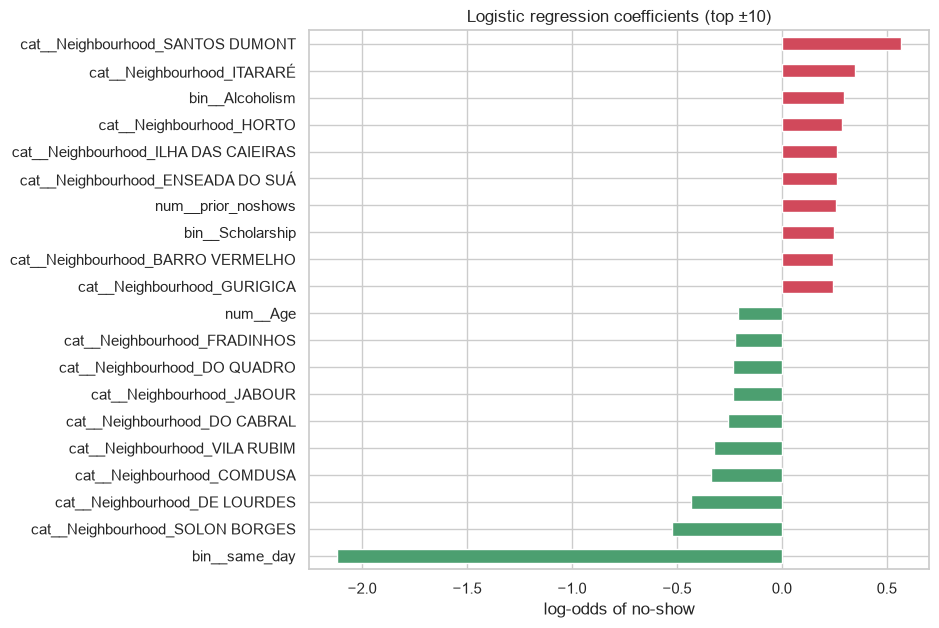

In [25]:
# Coefficients: positive = pushes towards no-show, negative = towards attending
names = logreg.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logreg.named_steps["clf"].coef_[0], index=names)
top = pd.concat([coefs.nlargest(10), coefs.nsmallest(10)]).sort_values()
top.plot.barh(figsize=(8, 7), color=np.where(top > 0, "#D1495B", "#4C9F70"))
plt.title("Logistic regression coefficients (top ±10)"); plt.xlabel("log-odds of no-show");

## 9. Tree-based models

In [26]:
rf = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced_subsample",
                                   n_jobs=-1, random_state=RANDOM_STATE)),
])
rf.fit(X_train, y_train)
p_rf = evaluate("Random Forest", rf)

hgb = Pipeline([
    ("prep", ColumnTransformer([
        ("num", "passthrough", NUMERIC + BINARY),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False), CATEGORICAL),
    ])),
    ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_leaf_nodes=31,
                                           early_stopping=True, random_state=RANDOM_STATE)),
])
hgb.fit(X_train, y_train)
p_hgb = evaluate("Gradient Boosting", hgb)

Random Forest {'ROC-AUC': 0.731, 'PR-AUC': 0.338, 'Accuracy': 0.602, 'No-show recall@0.5': 0.788, 'Brier': 0.202}
Gradient Boosting {'ROC-AUC': 0.734, 'PR-AUC': 0.341, 'Accuracy': 0.815, 'No-show recall@0.5': 0.021, 'Brier': 0.136}


**Learning note.** Trees don't need scaling and capture non-linear effects (e.g. no-show rising quickly for the first 2 weeks of lead time, then flattening) and interactions (e.g. young + long lead). Gradient boosting is usually the strongest on tabular data like this.

Cross-validation on the training set gives a more stable estimate than a single split:

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, m in [("Logistic Regression", logreg), ("Gradient Boosting", hgb)]:
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    print(f"{name:20s} CV ROC-AUC = {s.mean():.3f} ± {s.std():.3f}")

Logistic Regression  CV ROC-AUC = 0.726 ± 0.004
Gradient Boosting    CV ROC-AUC = 0.747 ± 0.005


## 10. Evaluation — comparing models

In [28]:
pd.DataFrame(results).T.round(3).sort_values("ROC-AUC", ascending=False)

,ROC-AUC,PR-AUC,Accuracy,No-show recall@0.5,Brier
Gradient Boosting,0.734,0.341,0.815,0.021,0.136
Random Forest,0.731,0.338,0.602,0.788,0.202
Logistic Regression,0.723,0.328,0.583,0.813,0.213
Baseline (always attend),0.500,0.185,0.815,0.000,0.185


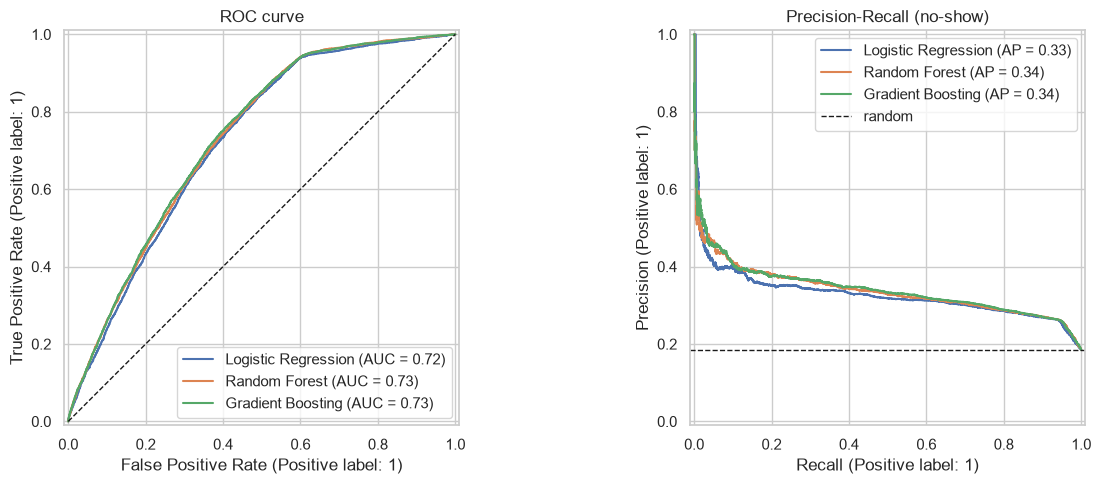

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in [("Logistic Regression", p_lr), ("Random Forest", p_rf), ("Gradient Boosting", p_hgb)]:
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("ROC curve")
axes[1].axhline(y_test.mean(), c="k", ls="--", lw=1, label="random"); axes[1].set_title("Precision-Recall (no-show)")
axes[1].legend(); plt.tight_layout()

**Learning note — why does Gradient Boosting catch 0 no-shows at 0.5 yet have the best ROC-AUC?** It wasn't trained with class weights, so its probabilities stay realistic (few referrals ever exceed 50% no-show risk). Its *ranking* is still good — it just needs a lower threshold (section 11). The 0.5 threshold is a default, not a law.

**Learning note — realistic expectations.** On this dataset, published work typically lands around **ROC-AUC 0.70–0.75** without leakage. If you ever see 0.95+, suspect leakage first, not genius. No-shows depend on things we don't observe (weather, transport, how the patient feels that day), so there's a ceiling.

## 11. Choosing a decision threshold

The model outputs a probability; *you* decide the cut-off based on the cost of each mistake:

- **False negative** (missed no-show) → empty slot, patient misses care.
- **False positive** (flagged an attender) → an unnecessary reminder call. Cheap.

So we often accept many false positives to catch more no-shows. Below: pick the threshold that catches 70% of no-shows.

Threshold 0.236 → recall 70.0%, precision 30.8%
              precision    recall  f1-score   support

    Attended       0.90      0.64      0.75     17915
     No-show       0.31      0.70      0.43      4070

    accuracy                           0.65     21985
   macro avg       0.61      0.67      0.59     21985
weighted avg       0.79      0.65      0.69     21985



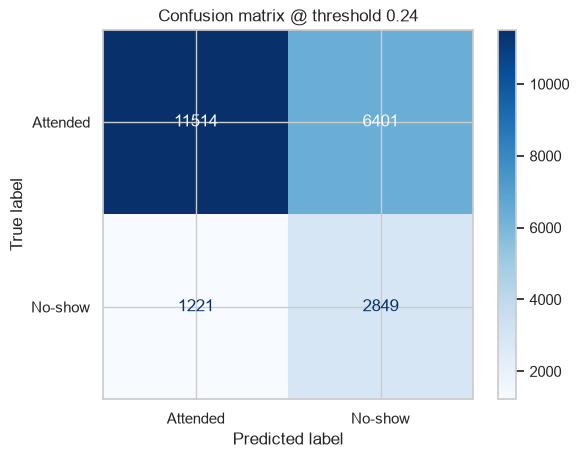

In [30]:
p_best = p_hgb   # swap for p_lr / p_rf to compare
prec, rec, thr = precision_recall_curve(y_test, p_best)
target_recall = 0.70
i = np.where(rec[:-1] >= target_recall)[0][-1]
threshold = thr[i]
print(f"Threshold {threshold:.3f} → recall {rec[i]:.1%}, precision {prec[i]:.1%}")

pred = (p_best >= threshold).astype(int)
print(classification_report(y_test, pred, target_names=["Attended", "No-show"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Attended", "No-show"]).plot(cmap="Blues")
plt.title(f"Confusion matrix @ threshold {threshold:.2f}");

**A more practical view — risk tiers.** Instead of one threshold, rank referrals by predicted success rate and act on the riskiest first.

,predicted_success,actual_success,n
risk_decile,,,
1,0.587,0.625,2199
2,0.664,0.674,2198
3,0.704,0.709,2199
4,0.741,0.750,2198
5,0.774,0.786,2199
6,0.806,0.818,2198
7,0.865,0.871,2198
8,0.951,0.962,2199
9,0.966,0.975,2198


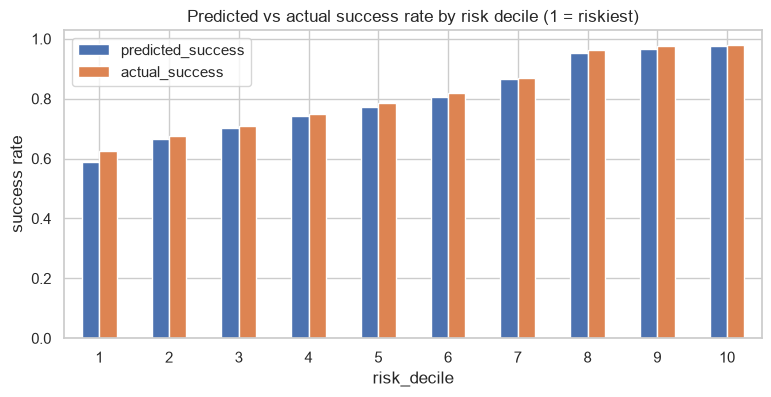

In [31]:
scored = test[["lead_days", "Age", "SMSReceived"]].copy()
scored["success_rate"] = 1 - p_best
scored["actual_no_show"] = y_test.values
scored["risk_decile"] = pd.qcut(scored["success_rate"].rank(method="first"), 10, labels=range(1, 11))  # 1 = riskiest
lift = scored.groupby("risk_decile", observed=True).agg(predicted_success=("success_rate", "mean"),
                                                         actual_success=("actual_no_show", lambda s: 1 - s.mean()),
                                                         n=("actual_no_show", "size"))
ax = lift[["predicted_success", "actual_success"]].plot.bar(figsize=(9, 4), rot=0)
ax.set_title("Predicted vs actual success rate by risk decile (1 = riskiest)"); ax.set_ylabel("success rate")
lift.round(3)

## 12. What drives the predictions? — permutation importance

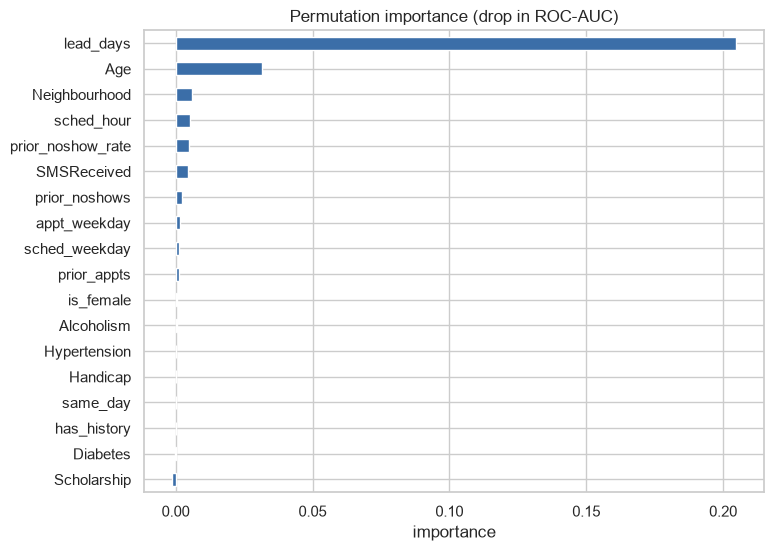

In [32]:
# Shuffle one column at a time on the TEST set and measure how much ROC-AUC drops
sample = X_test.sample(min(len(X_test), 8000), random_state=RANDOM_STATE)
imp = permutation_importance(hgb, sample, y_test.loc[sample.index], scoring="roc_auc",
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp_s = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
imp_s.plot.barh(figsize=(8, 6), color="#3B6EA8")
plt.title("Permutation importance (drop in ROC-AUC)"); plt.xlabel("importance");

**Learning note.** Permutation importance is model-agnostic and measured on unseen data, so it's more trustworthy than a tree's built-in `feature_importances_` (which favours high-cardinality features). Remember: importance ≠ causation — `SMSReceived` might look important only because it's a proxy for lead time.

## 13. Calibration — can we trust "72% success rate"?

If we want to report a **success rate** per referral, the probabilities themselves must be honest: among referrals predicted at 70% success, ~70% should succeed.

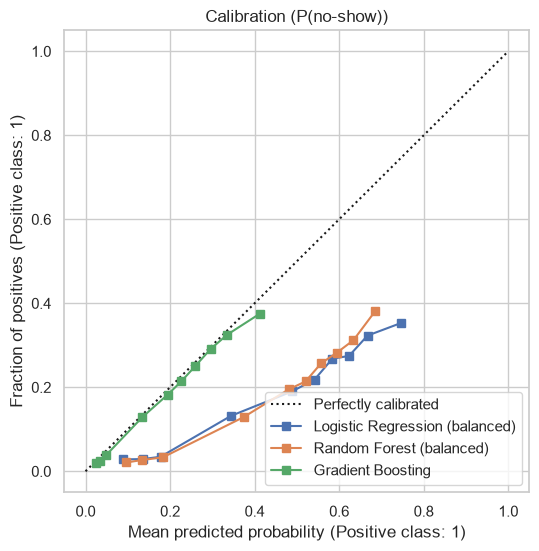

In [33]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, p in [("Logistic Regression (balanced)", p_lr), ("Random Forest (balanced)", p_rf), ("Gradient Boosting", p_hgb)]:
    CalibrationDisplay.from_predictions(y_test, p, n_bins=10, name=name, ax=ax, strategy="quantile")
ax.set_title("Calibration (P(no-show))");

**Learning note.** Models trained with `class_weight="balanced"` overestimate no-show probability (their curves sit below the diagonal). Gradient boosting trained on the natural class balance is usually close to the diagonal. To fix a mis-calibrated model, wrap it in `sklearn.calibration.CalibratedClassifierCV`. **Use class weights for ranking/flagging, unweighted (or calibrated) models for reporting rates.**

## 14. Save the model & score a new referral

In [44]:
import joblib
joblib.dump({"model": hgb, "features": FEATURES, "threshold": float(threshold)}, "referral_success_model.joblib")

def predict_success(referral: dict, bundle=joblib.load("referral_success_model.joblib")) -> float:
    """Return the predicted probability that the referral succeeds (patient attends)."""
    row = pd.DataFrame([referral])[bundle["features"]]
    return float(1 - bundle["model"].predict_proba(row)[0, 1])

new_referral = {
    "Age": 55, "lead_days": 21, "sched_hour": 9, "prior_appts": 2, "prior_noshows": 1, "prior_noshow_rate": 0.5,
    "is_female": 1, "Scholarship": 0, "Hypertension": 1, "Diabetes": 1, "Alcoholism": 1, "Handicap": 1,
    "SMSReceived": 1, "same_day": 1, "has_history": 0,
    "appt_weekday": "Monday", "sched_weekday": "Monday", "Neighbourhood": df["Neighbourhood"].mode()[0],
}
print(f"Predicted referral success rate: {predict_success(new_referral):.1%}")

Predicted referral success rate: 73.8%


## 15. Exercises — where to go next

1. **Leakage experiment:** compute `prior_noshow_rate` the *wrong* way (patient's overall no-show rate using all rows) and retrain. How much does ROC-AUC jump? Why is that result fake?
2. **Random vs time split:** redo section 6 with `train_test_split(..., stratify=y)`. Do scores change?
3. **Is `SMSReceived` known at booking time?** If SMS is decided later, remove it and see the impact.
4. **Hyperparameter tuning:** use `RandomizedSearchCV` on the gradient boosting model (learning_rate, max_leaf_nodes, l2_regularization).
5. **Calibrate** the logistic regression with `CalibratedClassifierCV(method="isotonic")` and redraw section 13.
6. **Cost-based threshold:** suppose a missed no-show costs 10 units and a reminder call costs 1. Find the threshold that minimises total cost.
7. **Fairness check:** compare recall and precision across `age_group`, `is_female` and `Scholarship`. Is the model equally good for everyone?
8. **Explainability:** install `shap` and plot SHAP values for a single high-risk referral.